# A Mediocre Solution Blocking a New Unit

Once a network has learned a mediocre solution, can a new unit with the right connectivity still learn the right
feature? The expected gradient on a new unit's input weights is proportional to $E[r\,\sigma'(z)\,x]$, $r$ being the
residual, $z$ the unit's pre-activation and $\sigma'$ its surrogate derivative. Were $\sigma'$ constant, this would be
proportional to $E[r x]$, which is zero once a linear readout of the inputs has converged. What is left comes from
$\sigma'$ varying with $z$: the higher-order part of the target, which takes far more samples to find (the information
exponent; Ben Arous et al., 2021). **Hypothesis:** a unit added after the readout has converged learns the target much
more slowly than a unit learning it alone.

**Problem.** Each sample has 10 standard normal inputs. The target is one LTU with zero threshold reading all of them
with $N(0, 1)$ weights, as $\pm 1$ (so it fires half the time, with zero mean and unit variance), plus $N(0, 0.1^2)$
noise; the best possible RMSE is 0.1 (dotted line). The best linear function of the inputs explains
$2/\pi \approx 64\%$ of the target's variance, an RMSE of about 0.61 (dashed line: the best linear learner). Each seed has its own target
weights.

**Learner.** One hidden LTU (sigmoid derivative backward) reading every input and a bias, its input weights starting
LeCun uniform, $U(-\sqrt{3/10}, \sqrt{3/10})$; one output reading the hidden unit, a bias, and, in two of the
conditions, every input directly (the *readout*), its weights starting at 0. As a new unit in unit search, the hidden
unit's output connection carries a fixed shadow weight of $\pm 1$ (random sign), which stands in for the real weight in
the backward pass while the real one is smaller in magnitude. *Two units*: the same, but with two hidden units, their
shadow weights fixed at +1 and -1, added together. Two learners, online, on half the squared error:
- *Network Autostep*: Autostep (`squared_inputs`, initial step-size $10^{-3}$, meta step-size 0.01, $\tau = 10^4$), with
  the hidden unit standardized online, $h = (b - m)/\sqrt{\max(m(1 - m), 0.01)}$, the backward pass going through the
  statistics.
- *SGD*: one step size for every weight, $2^{-11}$, $2^{-10}$, ... or $2^{-7}$, with the hidden unit's bit not standardized.

**Conditions.**
1. *LTU only*: no readout.
2. *LTU added at start*: the LTU and the readout both from step 0.
3. *LTU added later*: the readout learns alone for 100k steps from zero weights (enough to converge), then the LTU is
   added.

Network Autostep has 10 seeds per condition and SGD 5 per condition and step size, each with one unit and with two
units; the same seed gives every run the same
target, initial weights and samples. Every run goes on for 1M steps after the unit is added; the RMSE is averaged over
windows of 1k steps, and every run is plotted.

**Number of hidden units.** *LTU added later* again, with 2, 4, 8, 16 and 32 hidden LTUs added together, 10 seeds
each, by network Autostep with initial step-sizes and by SGD with step sizes $2^{-11}$, $2^{-10}$, ... and $2^{-7}$, the
units' shadow weights random signs or +1 and -1 alternately. Final performance is the RMSE over the last 10% of the 1M steps.

**Input and output step-sizes.** The same with network Autostep and shadow weights +1 and -1 alternately, but with the
initial step-size of the output's weights (the readout's included) fixed at $2^{-11}$, while that of the hidden units'
input weights is $2^{-11}$, $2^{-10}$, ... or $2^{-7}$.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 10                        # the target unit and the hidden unit read every input
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden unit (network Autostep)
INIT_STEP_SIZE = 1e-3                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.01, 1e4
SGD_STEP_SIZES = tuple(2.0 ** p for p in range(-11, -6))

# --- Experiment ---
CONDITIONS = {'LTU only': (False, 0), 'LTU added at start': (True, 0),   # (readout, steps before the LTU)
              'LTU added later': (True, 100_000)}
NUM_STEPS = 1_000_000                # steps after the unit is added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 10                         # network Autostep, per condition
SGD_SEEDS = 5                        # SGD, per condition and step size
UNIT_COUNTS = (2, 4, 8, 16, 32)      # hidden LTUs added later, in the second experiment (N_SEEDS seeds each)
OUTPUT_STEP_SIZE = 2.0 ** -11        # third experiment: Autostep's initial step-size for the output's weights

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at the hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)]; w['output'] is the output's weights over
    # [inputs (the readout), the hidden units, 1]. `mask` says which of the output's connections exist; the hidden
    # units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


def init_net(key, readout, units, slots, balanced, init_step_size=INIT_STEP_SIZE, output_step_size=None):
    # `units` hidden units in `slots` slots, the rest left empty. Each unit's shadow weight is a random sign, or +1 and
    # -1 alternately if balanced; an empty slot's is 0. The hidden units' input weights start LeCun uniform,
    # U(-sqrt(3 / N_INPUTS), sqrt(3 / N_INPUTS)); every other weight at 0. Autostep's step-sizes start at
    # init_step_size, the output's at output_step_size if given.
    weight_key, shadow_key = jax.random.split(key)
    signs = (jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0) if balanced
             else jax.random.rademacher(shadow_key, (slots,), dtype=jnp.float32))
    shadow = jnp.where(jnp.arange(slots) < units, signs, 0.0)
    mask = jnp.concatenate([jnp.full(N_INPUTS, readout), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(weight_key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_INPUTS)).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    opt = OPTIMIZER.init(w)
    steps = {'hidden': init_step_size, 'output': init_step_size if output_step_size is None else output_step_size}
    opt = opt._replace(beta={k: jnp.full_like(b, jnp.log(steps[k])) for k, b in opt.beta.items()})
    return Net(w, mask, opt, stats, shadow)


def learn(net, x, y, step_size=None):
    # One online update on half the squared error, by network Autostep, or by SGD at step_size (the hidden units' bits
    # not standardized), each shadow weight standing in for its hidden unit's output weight in the backward pass while
    # the real one is smaller in magnitude. Returns the new network and the squared error on this sample, before
    # learning from it. `probe` is zero; its gradient is the error arriving at each hidden unit.
    units = len(net.shadow)
    def loss_fn(w, probe):
        w = {**w, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = b if step_size is not None else standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0)[None], 'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {**grads, 'output': grads['output'] * net.mask}
    if step_size is None:
        updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    else:
        updates, opt = jax.tree.map(lambda g: -step_size * g, grads), net.opt
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [4]:
def train(net, key, add_step, num_steps, step_size=None):
    # num_steps online steps (network Autostep, or SGD at step_size), the hidden units added at add_step, on targets
    # from this seed's target weights. Returns each window's mean squared error.
    target_key, key = jax.random.split(key)
    target_w = jax.random.normal(target_key, (N_INPUTS,))

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        y = jnp.where(target_w @ x > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (1,))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y, step_size)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    n = num_steps // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run_all(step_sizes=(INIT_STEP_SIZE,), n_seeds=N_SEEDS, units=(1,), balanced=False, conditions=CONDITIONS,
            autostep=True, output_step_size=None):
    # Each of `conditions` with each number of hidden units on each of n_seeds seeds, by network Autostep with each of
    # step_sizes as its initial step-size (the output's weights' output_step_size if given), or by SGD at each of
    # step_sizes, vmapped together, the shadow weights as in init_net. Seed s gives every run the same target, initial weights and samples. Returns each run's RMSE over the
    # NUM_STEPS steps after its units are added, shaped (step size, condition, units, seed, window).
    runs = [(step_size, readout, add_step, n, seed) for step_size in step_sizes
            for readout, add_step in conditions.values() for n in units for seed in range(n_seeds)]
    step_size, readout, add_step, n_units, seed = (jnp.array(v) for v in zip(*runs))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    longest = max(a for _, a in conditions.values()) + NUM_STEPS
    nets = jax.vmap(lambda k, r, n, s: init_net(k, r, n, max(units), balanced, s, output_step_size))(
        keys(0), readout, n_units, step_size)
    started = perf_counter()
    train_all = jax.vmap(lambda n, k, a, s: train(n, k, a, longest, None if autostep else s))
    mse = np.asarray(jax.jit(train_all)(nets, keys(1), add_step, step_size))
    print(f'{len(runs)} runs in {perf_counter() - started:.0f}s')
    first = np.asarray(add_step) // WINDOW
    rmse = np.sqrt(np.stack([m[f:f + NUM_STEPS // WINDOW] for m, f in zip(mse, first)]))
    return rmse.reshape(len(step_sizes), len(conditions), len(units), n_seeds, -1)

## Runs

In [5]:
autostep = run_all()[0, :, 0]
two_units = run_all(units=(2,), balanced=True)[0, :, 0]
sgd = run_all(SGD_STEP_SIZES, SGD_SEEDS, autostep=False)[:, :, 0]
sgd_two_units = run_all(SGD_STEP_SIZES, SGD_SEEDS, units=(2,), balanced=True, autostep=False)[:, :, 0]

30 runs in 15s


30 runs in 20s


75 runs in 13s


75 runs in 15s


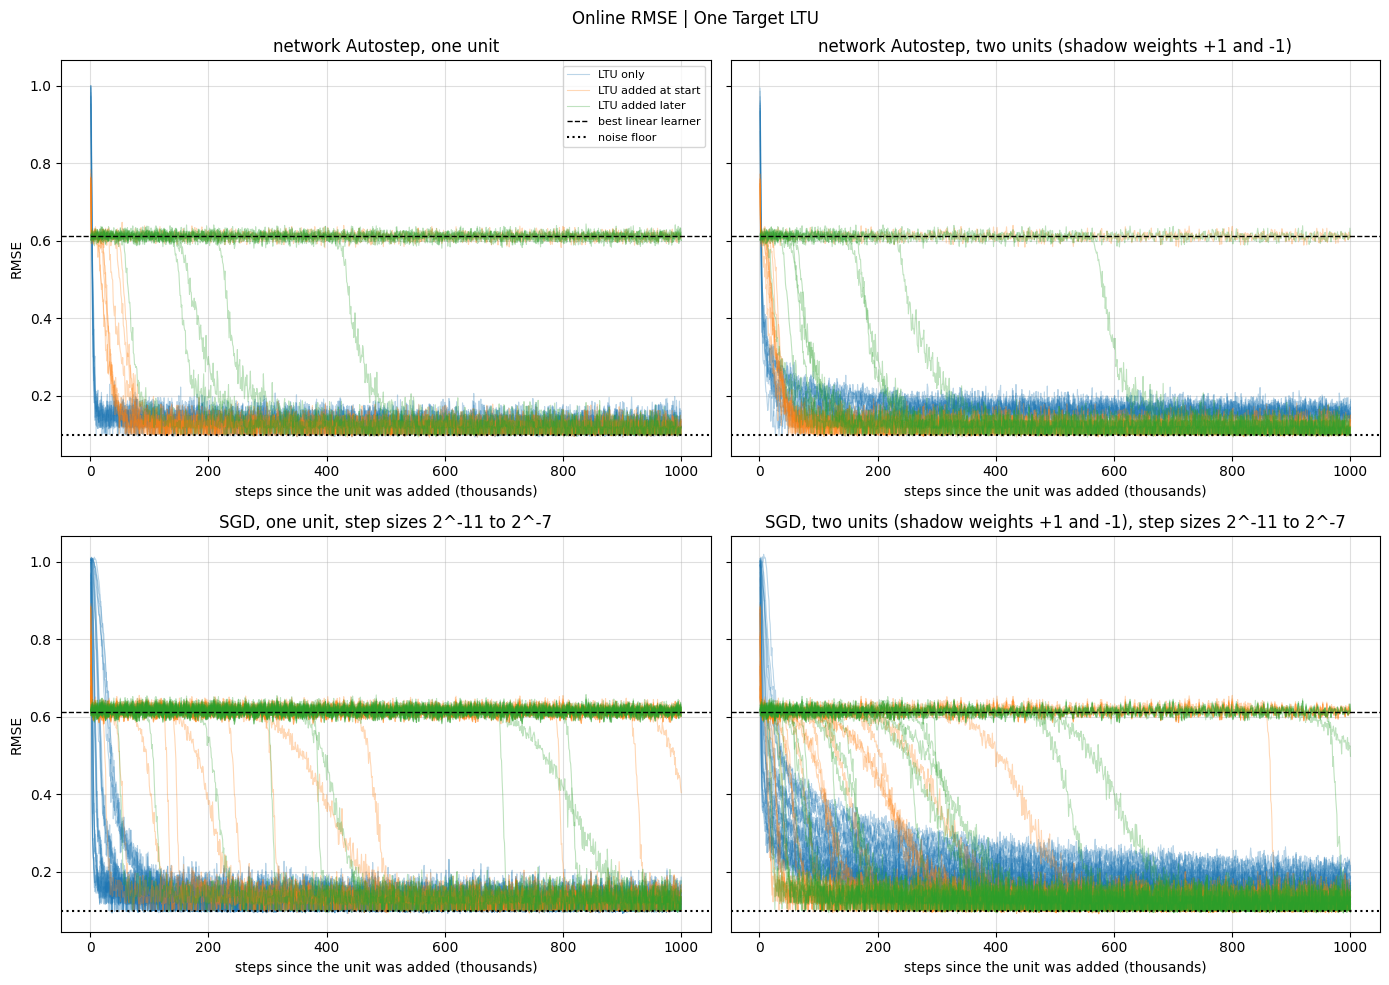

In [6]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
COLORS = dict(zip(CONDITIONS, ['tab:blue', 'tab:orange', 'tab:green']))
SGD_RANGE = f'2^{np.log2(SGD_STEP_SIZES[0]):.0f} to 2^{np.log2(SGD_STEP_SIZES[-1]):.0f}'
PANELS = {'network Autostep, one unit': autostep,   # (condition, run, window)
          'network Autostep, two units (shadow weights +1 and -1)': two_units,
          f'SGD, one unit, step sizes {SGD_RANGE}': np.concatenate(sgd, axis=1),
          f'SGD, two units (shadow weights +1 and -1), step sizes {SGD_RANGE}': np.concatenate(sgd_two_units, axis=1)}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)   # Autostep on the first row, SGD on the second
for ax, (learner, runs_by_condition) in zip(axes.flat, PANELS.items()):
    for condition, runs in zip(CONDITIONS, runs_by_condition):
        for i, run in enumerate(runs):
            ax.plot(STEPS / 1000, run, color=COLORS[condition], lw=0.8, alpha=0.3, label=None if i else condition)
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='steps since the unit was added (thousands)', title=learner)
    ax.grid(alpha=0.4)
for ax in axes[:, 0]:
    ax.set_ylabel('RMSE')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Online RMSE | One Target LTU')
fig.tight_layout()
plt.show()

## Number of hidden units

In [7]:
LATER = {'LTU added later': CONDITIONS['LTU added later']}
by_units = {(learner, balanced): run_all(SGD_STEP_SIZES, N_SEEDS, UNIT_COUNTS, balanced, LATER,   # (step size, units,
                                         autostep=learner == 'network Autostep')[:, 0]       # seed, window)
            for learner in ('network Autostep', 'SGD') for balanced in (False, True)}

250 runs in 23s


250 runs in 22s


250 runs in 15s


250 runs in 14s


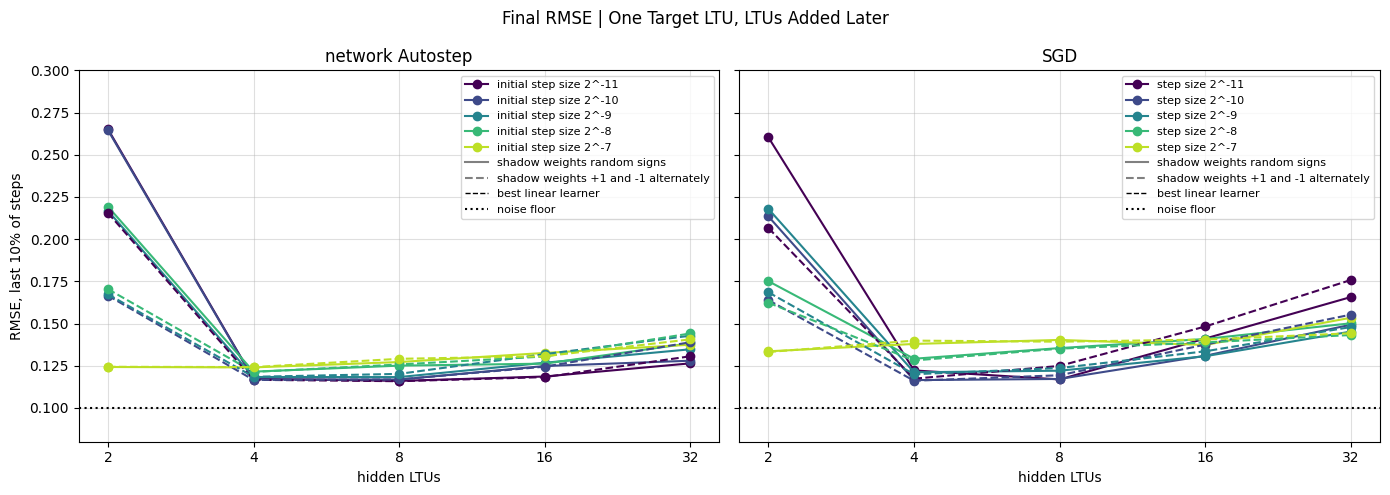

In [8]:
STEP_COLORS = plt.cm.viridis(np.linspace(0, 0.9, len(SGD_STEP_SIZES)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, learner in zip(axes, ('network Autostep', 'SGD')):
    for balanced, ls in ((False, '-'), (True, '--')):
        final = by_units[(learner, balanced)][..., -(NUM_STEPS // WINDOW // 10):].mean((-2, -1))   # (step size, units):
        for s, f, color in zip(SGD_STEP_SIZES, final, STEP_COLORS):                               # last 10%, then seeds
            label = None if balanced else f'{"initial " if learner == "network Autostep" else ""}step size 2^{np.log2(s):.0f}'
            ax.plot(UNIT_COUNTS, f, marker='o', ls=ls, color=color, label=label)
    ax.plot([], [], color='gray', ls='-', label='shadow weights random signs')
    ax.plot([], [], color='gray', ls='--', label='shadow weights +1 and -1 alternately')
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set_xscale('log', base=2)
    ax.set_xticks(UNIT_COUNTS, [str(n) for n in UNIT_COUNTS])
    ax.set(xlabel='hidden LTUs', title=learner)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
    ax.set_ylim(0.08, 0.3)
axes[0].set_ylabel('RMSE, last 10% of steps')
fig.suptitle('Final RMSE | One Target LTU, LTUs Added Later')
fig.tight_layout()
plt.show()

## Input and output step-sizes

In [9]:
fixed_output = run_all(SGD_STEP_SIZES, N_SEEDS, UNIT_COUNTS, True, LATER,   # (input step size, units, seed, window)
                       output_step_size=OUTPUT_STEP_SIZE)[:, 0]

250 runs in 23s


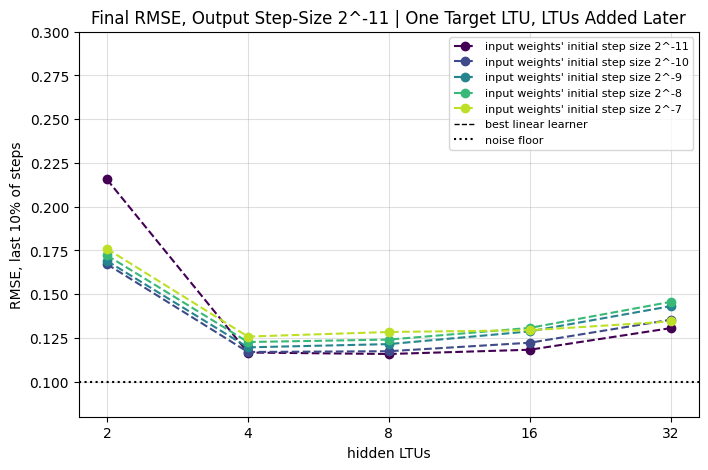

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
final = fixed_output[..., -(NUM_STEPS // WINDOW // 10):].mean((-2, -1))   # (input step size, units): last 10%, then seeds
for s, f, color in zip(SGD_STEP_SIZES, final, STEP_COLORS):
    ax.plot(UNIT_COUNTS, f, marker='o', ls='--', color=color, label=f"input weights' initial step size 2^{np.log2(s):.0f}")
ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set_xscale('log', base=2)
ax.set_xticks(UNIT_COUNTS, [str(n) for n in UNIT_COUNTS])
ax.set_ylim(0.08, 0.3)
ax.set(xlabel='hidden LTUs', ylabel='RMSE, last 10% of steps',
       title=f'Final RMSE, Output Step-Size 2^{np.log2(OUTPUT_STEP_SIZE):.0f} | One Target LTU, LTUs Added Later')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

A run *learns* the target when its RMSE over the last 10% of steps is below 0.3. Each of the three experiments
takes about a minute.

- **An LTU added later is often blocked.** With network Autostep, one LTU learns in 5 of 10 runs, and two with shadow
  weights +1 and -1 in 9 of 10. With SGD, from $2^{-11}$ to $2^{-7}$, one LTU learns in 1, 1, 1, 2 and 4 of 5 runs, and
  two LTUs in 3, 4, 4, 4 and 5.
- **An LTU only always learns** (final RMSE 0.11 to 0.20), and **an LTU added at start mostly does**: in 8 and 9 of 10
  runs with network Autostep (one and two LTUs), and with SGD in 1 to 4 of 5 runs with one LTU and 4 or 5 with two.
- **With 4 or more LTUs added later, every learner gets close to the floor**: a final RMSE of 0.12 to 0.14 at 4 and 8
  LTUs, for network Autostep and SGD at every (initial) step size, rising slightly to 0.13 to 0.18 at 32. With 2 LTUs it
  is 0.12 to 0.27, best at the largest step size. Network Autostep and SGD give nearly the same results at matching
  step sizes, and so do random and alternating shadow signs.
- **With the output's initial step-size held at $2^{-11}$, raising the input weights' barely matters.** All the
  differences are at 2 LTUs, and they are 0 to 2 blocked runs out of 10 (each about 0.61, the rest about 0.12). Raising
  the input weights' initial step-size from $2^{-11}$ to $2^{-10}$ goes from 2 blocked runs to 1, and higher values stay
  at 1; raising both to $2^{-7}$ gave 0 in the second experiment. From 4 LTUs on, every setting ends at 0.12 to 0.15.